# Crédito finito: factor común y estabilidad de cola
## Resumen
Extendemos el DP25 independiente a dependencia gaussiana, sin cambiar pesos ni PD. Los números se calculan abajo. La integración es numérica; referenciaGH256 no es verdad certificada. Este notebook es un experimento sintético de validación de algoritmo, no de cartera real.

## Modelo y supuestos
$A_i=\sqrt{\rho}Y+\sqrt{1-\rho}\epsilon_i$, independientes Y yε normales. $D_i=1[A_i\le\Phi^{-1}(p_i)]$. CondicionadoY=y, $p_i(y)=\Phi((\Phi^{-1}(p_i)-\sqrt{\rho}y)/\sqrt{1-\rho})$. rho es correlación de activoslatentes, no de defaults.

$P(L=l)=\int f_{DP}(l|y)\phi(y)dy\approx\sum_j(w_j/\sqrt{2\pi})f_{DP}(l|y_j)$. Nodos/pesos roots_hermitenorm integran pesoexp(-y²/2). PD conocidas, un factor, LGD/EADdeterministas y rejillaentera. No se redondean pesos aquí.

### Pregunta e hipótesis
¿ES99 granular sube≥50% respectoindependencia? ¿Últimos órdenes64→128 muestran deltaCDF≤1e−5 ydeltaES≤0,01? Se prueba además ortanteanalítico bivariado. El acuerdo entreórdenes no certifica error global; se incluye un caso donde falla claramente.

In [1]:
from pathlib import Path
import csv,json,math
from IPython.display import display,Image
from src.base import independent_pmf,tail
from src.factor import common_factor_pmf,stability_passed
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
summary=list(csv.DictReader((root/'results/summary.csv').open()))
for row in summary: print(row)
print('Oráculo analítico error:',metrics['analytic_orthant_max_error'])
print('SHA256 kernel25:',metrics['source_kernel_sha256'])

{'case': 'granular', 'regime': 'base', 'rho': '0.2', 'independent_var': '18.0', 'independent_es': '19.567309924665686', 'factor_var': '42.0', 'factor_es': '55.268596120694276', 'relative_es_increase': '1.824537268202878', 'last_stability_passed': 'True', 'last_es_difference_vs_reference': '-6.615152869926533e-11'}
{'case': 'granular', 'regime': 'stress', 'rho': '0.95', 'independent_var': '18.0', 'independent_es': '19.567309924665686', 'factor_var': '237.0', 'factor_es': '286.9751795598588', 'relative_es_increase': '13.666051729374951', 'last_stability_passed': 'False', 'last_es_difference_vs_reference': '-1.169991370368848'}
{'case': 'concentrated', 'regime': 'base', 'rho': '0.2', 'independent_var': '100.0', 'independent_es': '108.000000000029', 'factor_var': '110.0', 'factor_es': '120.98119851515332', 'relative_es_increase': '0.12019628254741521', 'last_stability_passed': 'True', 'last_es_difference_vs_reference': '1.2789769243681803e-13'}
{'case': 'concentrated', 'regime': 'stress', 

## Datos
Granular100×3 yconcentrada100+20×10,PD2%,pérdida máxima300,EL6. rho0,2base y0,95stress. GH16/32/64/128 frente256. MonteCarlo20semillas×20.000draws por cartera bajo mismoDGPfactor. Independencia no es una aproximación numérica del modeloρ0,2: es un baseline estructural distinto, incluido para medir su impacto.

granular MC RMSE ES99 vsGH256 1.1274939220028977
concentrated MC RMSE ES99 vsGH256 1.2338026006409506


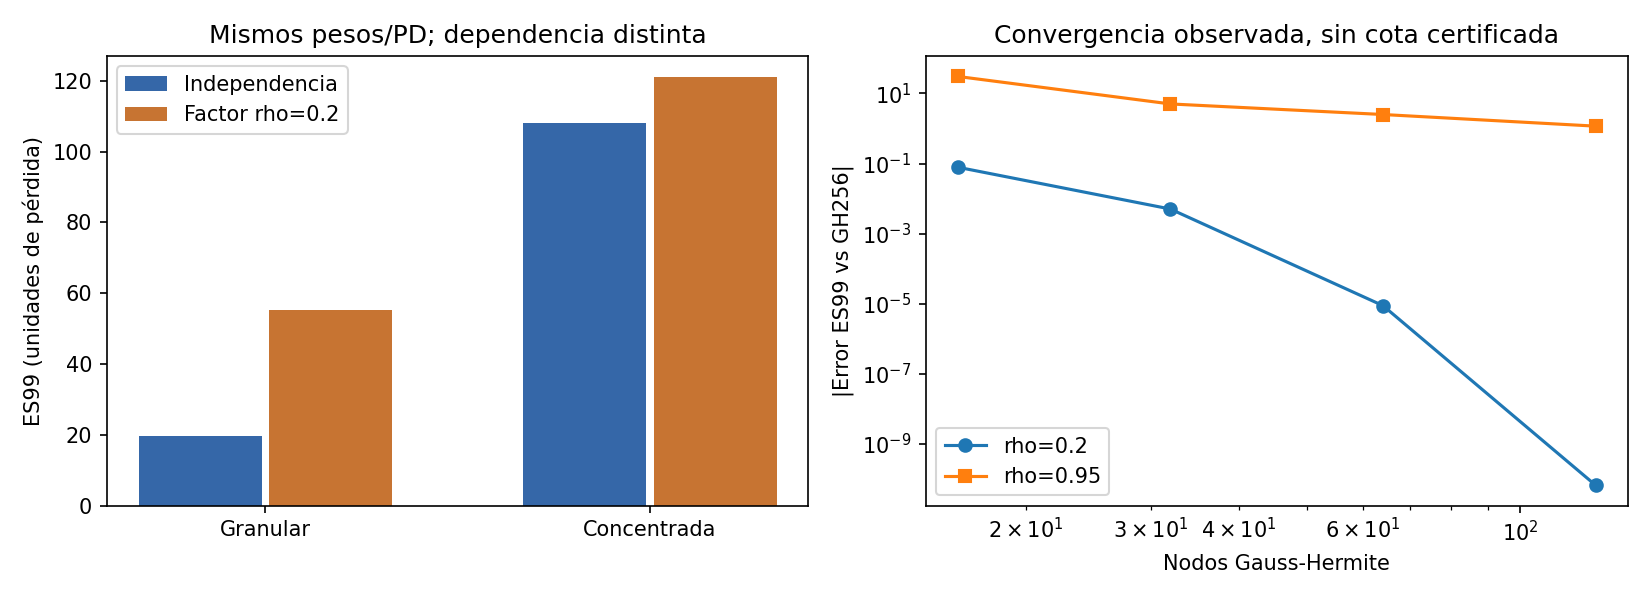

In [2]:
display(Image(filename=str(root/'results/audit.png')))
trials=list(csv.DictReader((root/'results/trials.csv').open()))
for name in ['granular','concentrated']:
 errors=[float(r['es_error_vs_reference']) for r in trials if r['case']==name]
 print(name,'MC RMSE ES99 vsGH256',math.sqrt(sum(e*e for e in errors)/len(errors)))

## Convergencia y referencias independientes
ParaPD1=PD2=.5, rho=.5, P(ambosdefaults)=1/4+asin(rho)/(2π); esta fórmula permite comprobar el cálculo sin compararlo solamente consigo mismo. rho0 vuelve exactamente alDP25. Conservar masa no basta para certificar la cola.

In [3]:
rho=.5
truth=.25+math.asin(rho)/(2*math.pi)
pmf=common_factor_pmf([1,1],[.5,.5],rho,64)
assert max(abs(a-b) for a,b in zip(pmf,[truth,1-2*truth,truth]))<=1e-12
assert common_factor_pmf([3,10],[.02,.03],0)==independent_pmf([3,10],[.02,.03])
assert metrics['hypothesis_passed']
print('Independent checks passed')

Independent checks passed


## Caso negativo: rho0,95
Las probabilidadescondicionales se vuelven abruptas y la quadratura moderada oscila. GH256 también es solo una referencia. Si stability_passed=False no debe presentarse la salida como convergida; True sigue siendo solo un diagnóstico local. No hay algoritmo de certificación adaptativo.

In [4]:
rows=list(csv.DictReader((root/'results/convergence.csv').open()))
for row in rows:
 if row['case']=='granular': print({k:row[k] for k in ['regime','nodes','var','es','es_error_vs_reference','stable_vs_previous','mass_error','mean_error']})
print('Tiempo global/memoriaPython:',metrics['seconds'],metrics['peak_tracemalloc_bytes'])

{'regime': 'base', 'nodes': '16', 'var': '42.0', 'es': '55.34741675058727', 'es_error_vs_reference': '0.07882062989299499', 'stable_vs_previous': 'False', 'mass_error': '0.0', 'mean_error': '5.329070518200751e-15'}
{'regime': 'base', 'nodes': '32', 'var': '42.0', 'es': '55.27364676506602', 'es_error_vs_reference': '0.005050644371742408', 'stable_vs_previous': 'False', 'mass_error': '1.2212453270876722e-15', 'mean_error': '8.881784197001252e-16'}
{'regime': 'base', 'nodes': '64', 'var': '42.0', 'es': '55.26860495418528', 'es_error_vs_reference': '8.833491001780658e-06', 'stable_vs_previous': 'False', 'mass_error': '6.661338147750939e-16', 'mean_error': '9.769962616701378e-15'}
{'regime': 'base', 'nodes': '128', 'var': '42.0', 'es': '55.268596120628125', 'es_error_vs_reference': '-6.615152869926533e-11', 'stable_vs_previous': 'True', 'mass_error': '2.220446049250313e-16', 'mean_error': '1.7763568394002505e-15'}
{'regime': 'stress', 'nodes': '16', 'var': '96.0', 'es': '256.304496574825', 

## Interpretación y límites
El incrementoES de base demuestra sensibilidad a dependencia, no precisión empírica del parámetro. La cartera concentrada ya tenía gran riesgo idiosincrático; su incremento relativo es menor, sin ser bajo riesgo. Rhoalto requiere otra estrategia de integración. El kernel25se reutiliza sin modificar; cinco fuentes primarias verificadas e informe14p detallan hipótesis, fallos y madurez. Próximo paso: integraciónadaptativa independiente, no publicar másdecimales de un resultado inestable.